# AI themes on Hacker News: what rises, what fades

This notebook looks at the stories collected by **AI News Radar** and asks two questions:

1. **Volume**: which share of the AI stories posted each day belongs to each theme?
2. **Attention**: which share of readers' engagement (points + comments) each theme gets?

The two can differ: a theme can be posted about a lot and ignored, or rarely posted about
and heavily discussed.

**Caveats.** Only complete UTC days are used (the first day of collection and the current
day are partial). Themes come from Gemini (prompt v2), which matched an independent
reference on 73% of a held-out sample (see the README), so small differences between
themes are within the labelling noise. With a few weeks of data, treat day-to-day moves
as anecdotes and look at the weekly view.

In [1]:
import sys
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from radar.config import THEMES
from radar.storage import load_posts
from radar import trends

COLORS = dict(zip(THEMES.values(), ["#4C78A8", "#F58518", "#54A24B", "#B279A2", "#E45756",
                                     "#72B7B2", "#EECA3B", "#9D755D", "#BAB0AC"]))
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})

posts = trends.prepare(load_posts(ROOT / "data" / "posts.csv"))
start, end = trends.complete_days(posts, datetime.now(timezone.utc).date())
df = trends.between(posts, start, end)
n_days = (end - start).days + 1
print(f"{len(df)} AI stories over {n_days} complete days, {start} to {end} "
      f"({len(df) / n_days:.0f} per day)")

627 AI stories over 5 complete days, 2026-11-12 to 2026-11-16 (125 per day)


## How many AI stories per day?

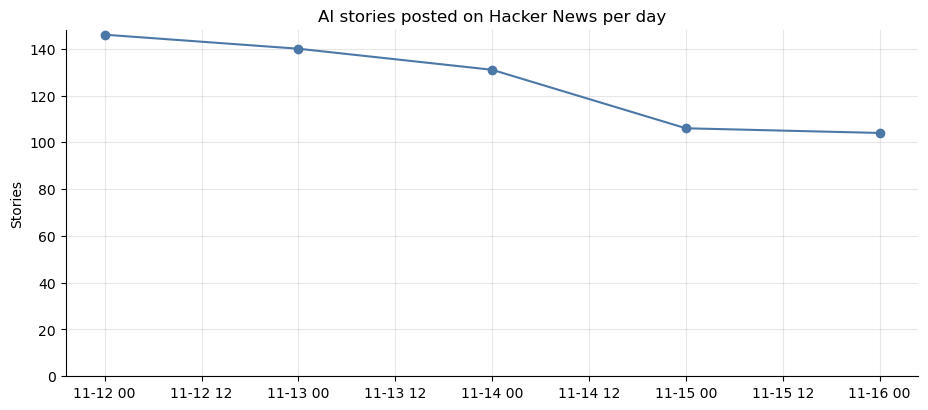

mean    125.0
min     104.0
max     146.0
Name: stories, dtype: float64

In [2]:
volume = trends.daily_volume(df)
ax = volume.plot(marker="o", color="#4C78A8", title="AI stories posted on Hacker News per day")
ax.set_xlabel(""); ax.set_ylabel("Stories"); ax.set_ylim(bottom=0)
plt.show()
volume.describe()[["mean", "min", "max"]].round(0)

## Theme share per day

Left: share of stories. Right: share of points + comments.

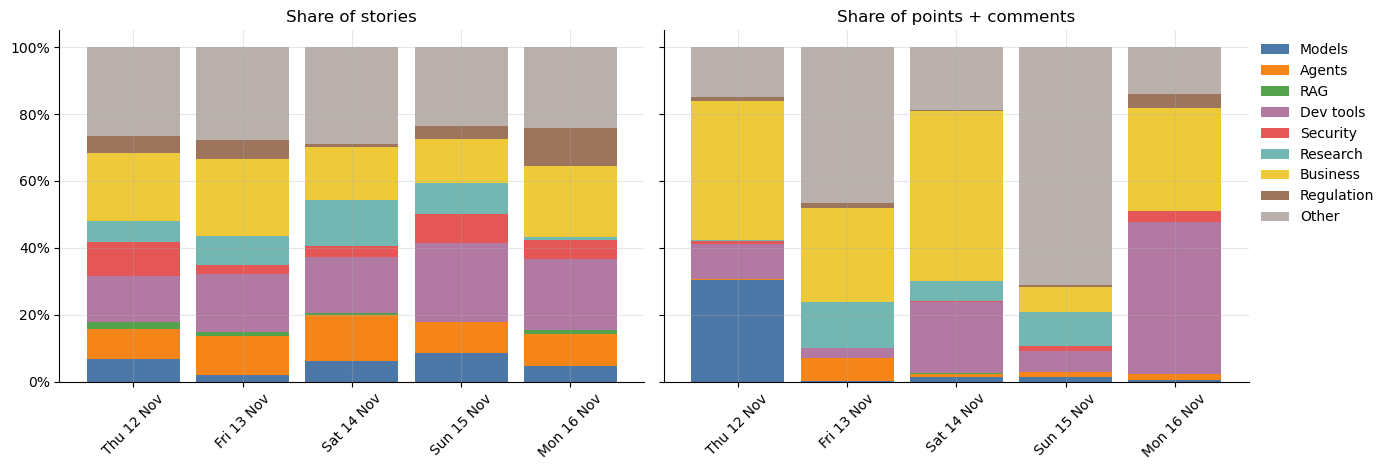

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, measure, title in zip(axes, ["volume", "attention"], ["Stories", "Points + comments"]):
    share = trends.theme_share(df, measure=measure).rename(columns=THEMES)
    share.index = share.index.strftime("%a %d %b")
    share.plot.bar(stacked=True, ax=ax, color=[COLORS[c] for c in share.columns],
                   width=0.85, legend=False, title=f"Share of {title.lower()}")
    ax.set_xlabel(""); ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
    ax.tick_params(axis="x", rotation=45)
axes[1].legend(loc="upper left", bbox_to_anchor=(1, 1), frameon=False)
plt.tight_layout(); plt.show()

## Volume versus attention, over the whole period

Points to the right of the diagonal get more attention than their share of stories.

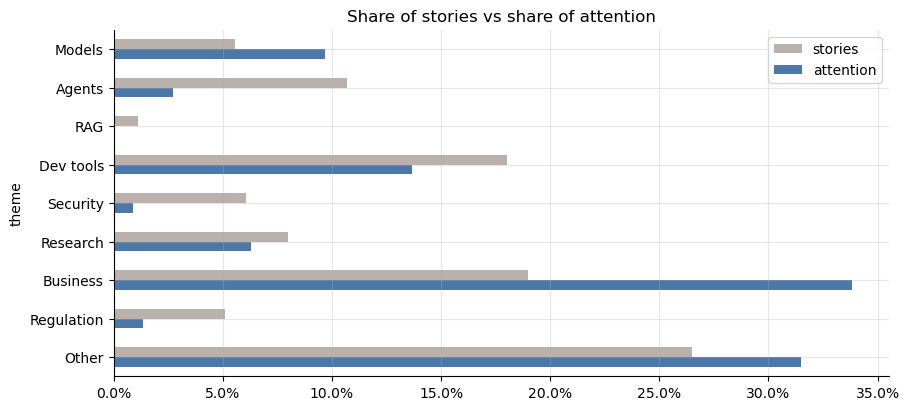

,stories,attention,attention / stories
theme,,,
Business,19%,34%,1.78
Models,6%,10%,1.74
Other,26%,32%,1.19
Research,8%,6%,0.79
Dev tools,18%,14%,0.76
Regulation,5%,1%,0.26
Agents,11%,3%,0.26
Security,6%,1%,0.15
RAG,1%,0%,0.06


In [4]:
totals = pd.DataFrame({
    "stories": df["theme"].value_counts(normalize=True),
    "attention": df.groupby("theme")["engagement"].sum() / df["engagement"].sum(),
}).reindex(list(THEMES)).fillna(0).rename(index=THEMES)
totals["attention / stories"] = totals["attention"] / totals["stories"]

ax = totals[["stories", "attention"]].plot.barh(color=["#BAB0AC", "#4C78A8"], figsize=(10, 4.5),
                                                title="Share of stories vs share of attention")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1)); ax.invert_yaxis()
plt.show()
totals.sort_values("attention / stories", ascending=False).style.format(
    {"stories": "{:.0%}", "attention": "{:.0%}", "attention / stories": "{:.2f}"})

## Rising and falling themes

Share of stories in the most recent days compared with the same number of days just before
(half of the period each, at most a week), in percentage points.

In [5]:
window = max(1, min(7, n_days // 2))
momentum = trends.theme_momentum(posts, end=end, window_days=window)
momentum["theme"] = momentum["theme"].map(THEMES)
print(f"Last {window} days to {end} vs the {window} days before")
momentum.style.format({"recent": "{:.0%}", "previous": "{:.0%}", "change": "{:+.1f}"})

Last 2 days to 2026-11-16 vs the 2 days before


,theme,recent,previous,stories,change
0,Dev tools,22%,17%,47,+5.4
1,Regulation,8%,3%,16,+4.3
2,Security,7%,3%,15,+4.2
3,Models,7%,4%,14,+2.6
4,RAG,0%,1%,1,-0.6
5,Business,17%,20%,36,-2.4
6,Agents,10%,13%,20,-3.0
7,Other,24%,28%,50,-4.6
8,Research,5%,11%,11,-5.8


In [6]:
attention_momentum = trends.theme_momentum(posts, end=end, window_days=window, measure="attention")
attention_momentum["theme"] = attention_momentum["theme"].map(THEMES)
attention_momentum[["theme", "recent", "previous", "change"]].style.format(
    {"recent": "{:.0%}", "previous": "{:.0%}", "change": "{:+.1f}"})

,theme,recent,previous,change
0,Dev tools,26%,10%,+15.9
1,Other,43%,36%,+6.7
2,Security,2%,0%,+2.1
3,Regulation,2%,1%,+1.2
4,Models,1%,1%,+0.4
5,RAG,0%,0%,+0.0
6,Agents,2%,5%,-3.2
7,Research,5%,11%,-5.6
8,Business,19%,36%,-17.5


## What drove the attention: the most discussed story of each theme

In [7]:
best = (df.sort_values("engagement", ascending=False).groupby("theme").head(1)
        .assign(theme=lambda d: d["theme"].map(THEMES))
        [["theme", "day", "title", "score", "num_comments"]])
best.set_index("theme").reindex(THEMES.values()).dropna()

,day,title,score,num_comments
theme,,,,
Models,2026-11-12,Gemini 4 Hydrogen,572,353
Agents,2026-11-13,Brave Search API now accepts agentic payments ...,262,151
RAG,2026-11-12,AI search is recommending fake retail websites,8,0
Dev tools,2026-11-16,Windows 11 is collecting data on which coding ...,652,511
Security,2026-11-16,FBI says Artex AI open-source hacking tool use...,46,10
Research,2026-11-13,"AI unlocks Gödel's notebooks, said to contain ...",443,111
Business,2026-11-12,Anthropic IPO,1005,921
Regulation,2026-11-13,Are we just going to ignore that books are des...,51,40
Other,2026-11-15,All AI-generated code should be Open Source,1274,664


## Where the links point

In [8]:
trends.top_domains(df, n=12)

,domain,stories,engagement
0,github.com,76,1365
1,youtube.com,23,1960
2,nytimes.com,9,237
3,arxiv.org,9,20
4,huggingface.co,8,109
5,reuters.com,8,62
6,medium.com,8,28
7,openai.com,7,217
8,twitter.com,7,57
9,theguardian.com,6,650


## Findings

*Written on 17 November 2026, from the first 5 complete days (12 to 16 November, 627 stories). The charts above update when the notebook is re-run; this text does not.*

- **Volume is steady**: 104 to 146 AI stories a day, about 125 on average, so roughly one Hacker News story in ten is about AI.
- **Attention is concentrated in a few hits.** The 10 most discussed stories take 52% of all points + comments; the median AI story gets 2 to 4. The attention view is therefore driven by single stories (an IPO, a viral essay) more than by themes.
- **What gets discussed is not what gets posted.** *Business* is 19% of the stories but 34% of the attention, and *models* 6% of the stories but 10% of the attention: launches and money draw the crowd. *Agents* is the opposite: 11% of the stories but under 3% of the attention, mostly Show HN tools that few people comment on. *Security*, *regulation* and *RAG* are also discussed far less than they are posted.
- **GitHub is the most linked site (12% of the stories), but YouTube draws more engagement** with a third as many links, thanks to a couple of widely discussed talks.
- **Rising and falling themes are not meaningful yet.** Over the last 2 days, *dev tools* (+5 points), *regulation* (+4) and *security* (+4) rose while *research* (−6) and *other* (−5) fell, but with about 100 stories a day a 4-point move is 4 stories. Week-over-week comparisons will be worth reading after a month of data.
- **Caveat**: themes come from an LLM that matches an independent reference about 73% of the time, so differences of a few points between themes are within the labelling noise.
